# Padrão de loop (pizza) — `code_path.png`

Mesmo gráfico de `graphic/code/grafico_caminho_percorrido.ipynb`. Os números vêm da coluna *Code loop* de `../data/tabela_de_codigos_artefatos.csv` (cada estudo em uma categoria). Cores iguais às de `grafico_tipo_codigo.ipynb` (`cores.py`).

In [1]:
import sys
sys.path.insert(0, "../scripts")   # graficos/scripts: dados_artefatos.py, paleta_grupos.py

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import dados_artefatos as da
from cores import LOOP   # código do loop -> (rótulo, cor)

In [2]:
# rótulo de cada código na pizza (com quebra de linha)
rotulos = {"CL1": "Loop closed\nby the LLM", "CL2": "Direct\n(no review or repair)", "CL3": "Other mechanism",
           "CL4": "Loop closed\nby a human", "CL5": "Chained loops\n(LLM + human)", "CL6": "Human only"}
contagem = da.contagem("Code loop")
ordem = sorted(rotulos, key=lambda c: -contagem[c])          # fatias em ordem decrescente
dados = [(rotulos[c], int(contagem[c]), LOOP[c][1]) for c in ordem]
labels_pizza = [d[0] for d in dados]
valores_pizza = [d[1] for d in dados]
cores_pizza = [d[2] for d in dados]

total = sum(valores_pizza)
print(contagem.to_dict(), "total =", total)
assert total == len(da.estudos("Code loop"))
percentuais = [round(v / total * 100) for v in valores_pizza]

{'CL1': 108, 'CL2': 91, 'CL3': 49, 'CL4': 10, 'CL5': 1, 'CL6': 16} total = 275


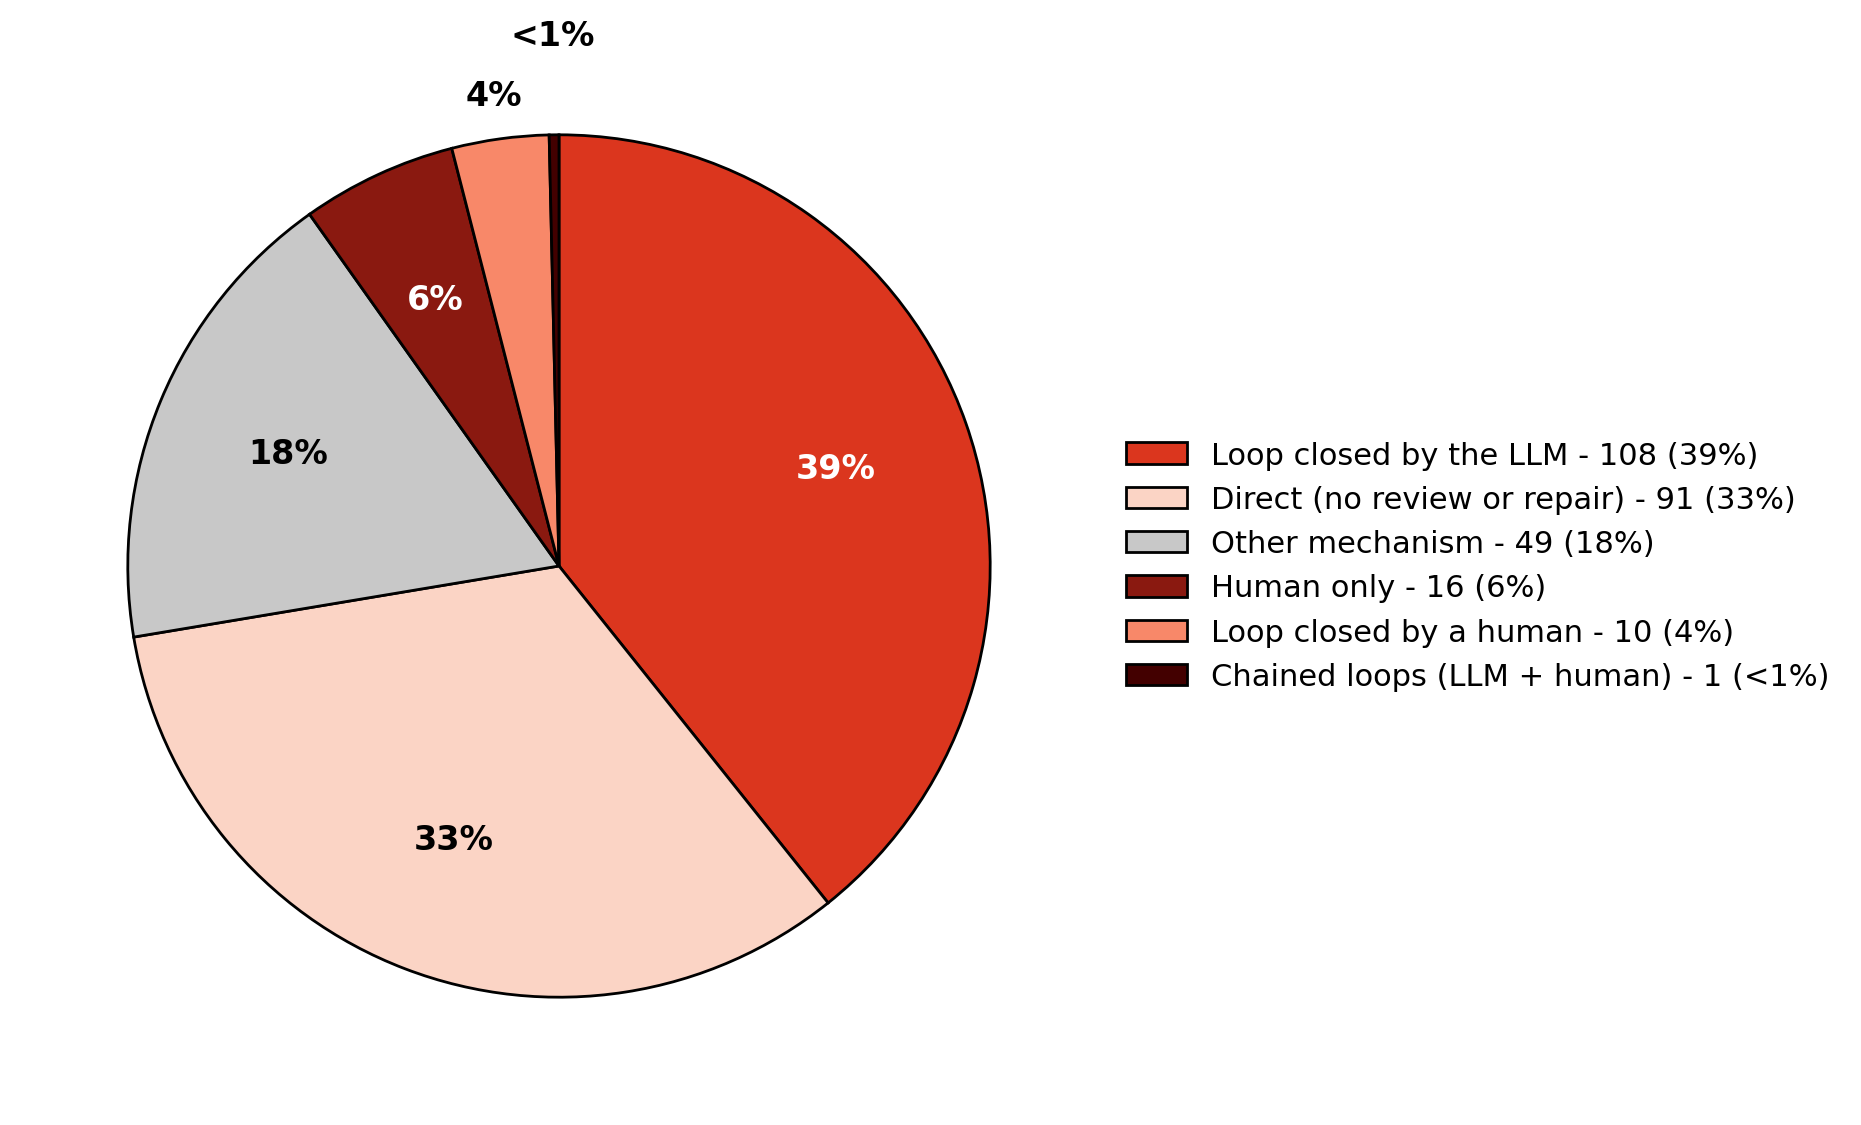

In [3]:
def cor_texto_legivel(rgba):
    r, g, b, _ = rgba
    return "black" if 0.299 * r + 0.587 * g + 0.114 * b > 0.55 else "white"

fig, ax = plt.subplots(figsize=(10, 7), dpi=200)

# porcentagem dentro da fatia; fatias < 5% recebem o número do lado de fora
wedges, _ = ax.pie(
    valores_pizza,
    colors=cores_pizza,
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "black", "linewidth": 1},
)
texto_pct = lambda v, pct: f"{pct}%" if pct >= 1 else "<1%"      # fatia que arredonda para 0% vira "<1%"
fora = 0                                                          # fatias pequenas seguidas: rótulos em alturas alternadas
for w, v, pct in zip(wedges, valores_pizza, percentuais):
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    if pct >= 5:
        r, cor, fora = 0.68, cor_texto_legivel(w.get_facecolor()), 0
    else:
        r, cor = 1.1 + 0.13 * (fora % 2), "black"
        fora += 1
    ax.text(r * np.cos(ang), r * np.sin(ang), texto_pct(v, pct), ha="center", va="center",
            fontsize=12, fontweight="bold", color=cor)

legend_handles = [
    Patch(facecolor=cor, edgecolor="black", label=f"{l.replace(chr(10), ' ')} - {v} ({texto_pct(v, p)})")
    for l, cor, v, p in zip(labels_pizza, cores_pizza, valores_pizza, percentuais)
]
ax.legend(
    handles=legend_handles,
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    frameon=False,
    fontsize=11,
)

ax.set_aspect("equal")
ax.axis("off")

plt.savefig("code_path.png", bbox_inches="tight", dpi=200)
plt.savefig("code_path.pdf", bbox_inches="tight")
plt.show()